In [1]:
import numpy as np
import pandas as pd
import OpenEXR
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image, ImageDraw

ds_path = Path(r"C:\Users\sol77\Desktop\ML-For-CV-Robustness\datasets\datasetGTCombined.csv")

Path.is_file(ds_path)

ds = pd.read_csv(ds_path)

shadowParts = ds[ds["illumR"] < 150]
shadowParts

,grviIn,meanRefR,meanRefG,illumR,illumG,blockIdx,sunRoll,sunPitch,sunYaw,camRoll,camPitch,camYaw,grviOut
333620,0.123112,0.028007,0.029256,1.638,2.241,0.0,180.0,-63.812729,-56.074120,0.0,-19.026,-0.0,0.08
333621,0.043090,0.103939,0.088035,1.638,2.241,1.0,180.0,-63.812729,-56.074120,0.0,-19.026,-0.0,0.08
333622,-0.011000,0.098665,0.080628,1.638,2.241,2.0,180.0,-63.812729,-56.074120,0.0,-19.026,-0.0,0.08
333623,-0.013016,0.134701,0.109012,1.638,2.241,3.0,180.0,-63.812729,-56.074120,0.0,-19.026,-0.0,0.08
333624,-0.017976,0.144108,0.116267,1.638,2.241,4.0,180.0,-63.812729,-56.074120,0.0,-19.026,-0.0,0.08
...,...,...,...,...,...,...,...,...,...,...,...,...,...
667215,0.081585,0.116098,0.116494,1.226,1.498,15.0,180.0,-42.301559,-85.835487,-0.0,-22.204,-180.0,0.26
667216,0.059388,0.139158,0.136244,1.226,1.498,16.0,180.0,-42.301559,-85.835487,-0.0,-22.204,-180.0,0.26
667217,0.013291,0.156488,0.144428,1.226,1.498,17.0,180.0,-42.301559,-85.835487,-0.0,-22.204,-180.0,0.26
667218,0.144914,0.111864,0.126774,1.226,1.498,18.0,180.0,-42.301559,-85.835487,-0.0,-22.204,-180.0,0.26


In [2]:
shadowParts = ds[ds["illumR"] < 150].copy()

stats = shadowParts.groupby("grviOut")["grviIn"].agg(
    ["count", "mean", "std", "min", "max"]
)

print(stats)

         count      mean        std          min         max
grviOut                                                     
0.08       480  0.057081   0.438313    -6.058137    6.226472
0.10       908 -0.036235   1.367287   -24.222715    1.319544
0.12       480  0.072930   0.413559    -8.320835    1.853732
0.14      1148  0.135611   0.611983    -6.517088    9.999226
0.16      1152 -0.361612  12.200957  -235.377930   73.296967
0.18       180 -0.029441   0.164079    -1.519300    0.760878
0.20       580  0.204894   1.137041    -1.226969   24.606936
0.22      2192  0.215304   1.721734   -37.629642   27.793020
0.24      1388  0.040972   6.789010  -234.382538   93.747551
0.26      8644 -0.134022   8.958337  -604.156311    7.746958
0.28      2844 -0.400204  19.908216 -1009.090332   27.543467
0.30     10392 -0.024366   7.487053  -603.959167   26.683277
0.32      9832  0.215738   6.290741  -235.296188  295.829681
0.34     11172  0.106803   4.176259  -234.782074  105.156586
0.36     18168  0.185533

In [3]:
invalid = shadowParts[
    (shadowParts["grviIn"] < -1) |
    (shadowParts["grviIn"] > 1)
]

print("Total shadowed samples:", len(shadowParts))
print("Invalid GRVI samples:", len(invalid))

print(invalid[[
    "grviOut", "grviIn",
    "meanRefR", "meanRefG",
    "illumR", "illumG",
    "blockIdx", "sunPitch", "sunYaw"
]].sort_values("grviIn"))

Total shadowed samples: 74320
Invalid GRVI samples: 1457
        grviOut       grviIn  meanRefR  meanRefG   illumR   illumG  blockIdx  \
392320     0.28 -1009.090332  0.041934  0.035756    0.268    0.382       0.0   
559200     0.26  -604.156311  0.006959  0.013994    0.268    0.382       0.0   
392420     0.30  -603.959167  0.019089  0.026378    0.268    0.382       0.0   
552802     0.16  -235.377930  0.027535  0.030714    0.253    0.360       2.0   
385850     0.32  -235.296188  0.158754  0.142669    0.253    0.360      10.0   
...         ...          ...       ...       ...      ...      ...       ...   
426518     0.38   122.362000  0.011534  0.019438    0.407    0.583      18.0   
543267     0.32   148.467484  0.027415  0.041653    0.325    0.442       7.0   
385853     0.32   173.473831  0.119434  0.126533    0.253    0.360      13.0   
387061     0.36   286.540771  0.000068  0.000121  139.605  126.744       1.0   
543260     0.32   295.829681  0.003525  0.009276    0.325    0.

In [4]:
shadowParts = ds[ds["illumR"] < 150]

In [5]:
shadowParts = shadowParts.copy()

shadowParts["sumRef"] = (
    shadowParts["meanRefR"] +
    shadowParts["meanRefG"]
)

shadowParts["grviFromRef"] = (
    (shadowParts["meanRefG"] - shadowParts["meanRefR"]) /
    shadowParts["sumRef"]
)

print(shadowParts[[
    "grviOut", "grviIn",
    "meanRefR", "meanRefG",
    "sumRef", "grviFromRef"
]].sort_values("sumRef").head(20))

        grviOut    grviIn  meanRefR  meanRefG    sumRef  grviFromRef
387076     0.36  0.015080  0.000010  0.000039  0.000049     0.599902
387065     0.36  0.535945  0.000011  0.000040  0.000051     0.575693
387077     0.36  0.248308  0.000012  0.000041  0.000053     0.561093
387071     0.36 -0.736816  0.000011  0.000043  0.000054     0.579570
387072     0.36  0.654337  0.000012  0.000044  0.000056     0.562602
387066     0.36  2.387508  0.000013  0.000046  0.000059     0.568793
387075     0.36  1.053053  0.000014  0.000050  0.000064     0.556190
387067     0.36  0.374837  0.000016  0.000052  0.000067     0.536543
387073     0.36  2.339185  0.000018  0.000051  0.000070     0.474882
387070     0.36 -0.438619  0.000020  0.000053  0.000072     0.457761
387064     0.36  0.343374  0.000022  0.000054  0.000076     0.421324
387079     0.36  0.088026  0.000023  0.000053  0.000076     0.401915
544379     0.38  4.858221  0.000022  0.000069  0.000092     0.511372
387074     0.36  0.459485  0.00002

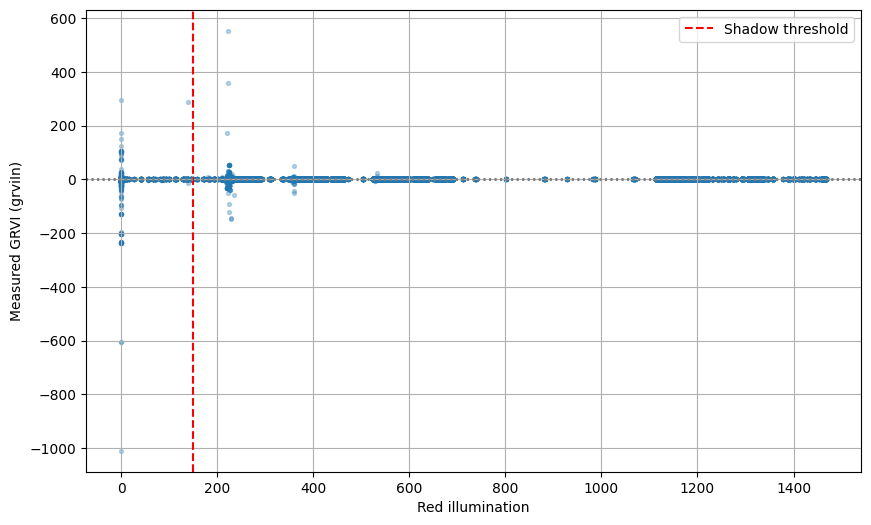

In [6]:
plt.figure(figsize=(10, 6))

plt.scatter(
    ds["illumR"],
    ds["grviIn"],
    s=8,
    alpha=0.3
)

plt.axvline(150, color="red", linestyle="--",
            label="Shadow threshold")

plt.axhline(-1, color="gray", linestyle=":")
plt.axhline(1, color="gray", linestyle=":")

plt.xlabel("Red illumination")
plt.ylabel("Measured GRVI (grviIn)")
plt.legend()
plt.grid()
plt.show()